In [8]:
from plot_clustering import get_labels_coordinates, get_groundtruth_role_id, get_magic_kmeans_role_id, get_dbscan_role_id

data_path = "../../data/SoccerNetGS/valid"
videos_list = ['SNGS-021', 'SNGS-039', 'SNGS-078']
embeddings_directory = "../../output/tmp/GAM-292_embeddings"

labels_coordinates = get_labels_coordinates(embeddings_directory, videos_list)
groundtruth_role_id = get_groundtruth_role_id(data_path, videos_list, labels_coordinates)
magic_kmeans_role_id = get_magic_kmeans_role_id(embeddings_directory, videos_list)
dbscan_role_id = get_dbscan_role_id(embeddings_directory, videos_list)

Videos iteration to get DBScan role_id: 100%|██████████| 3/3 [00:01<00:00,  1.76it/s]


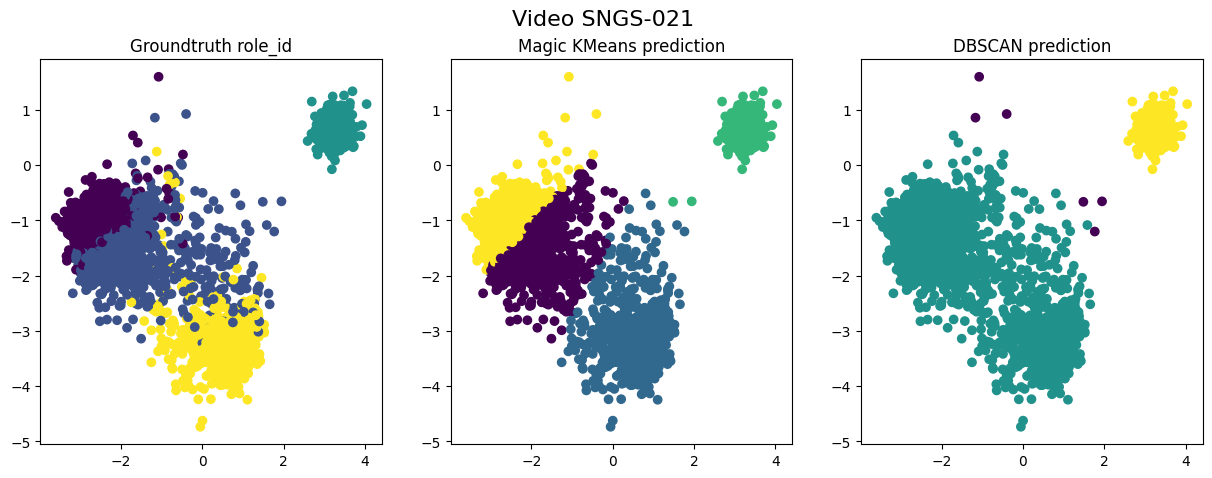

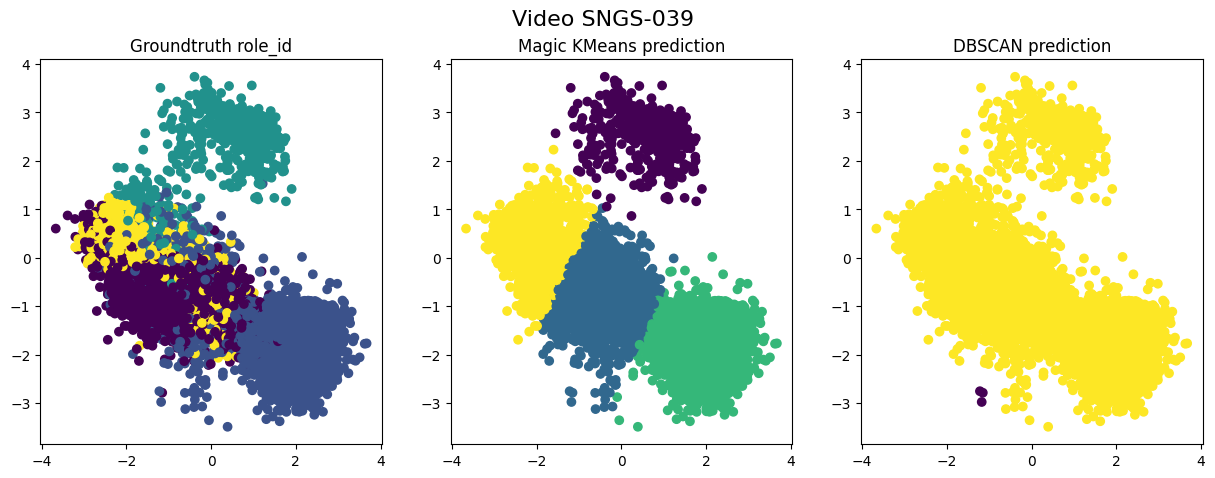

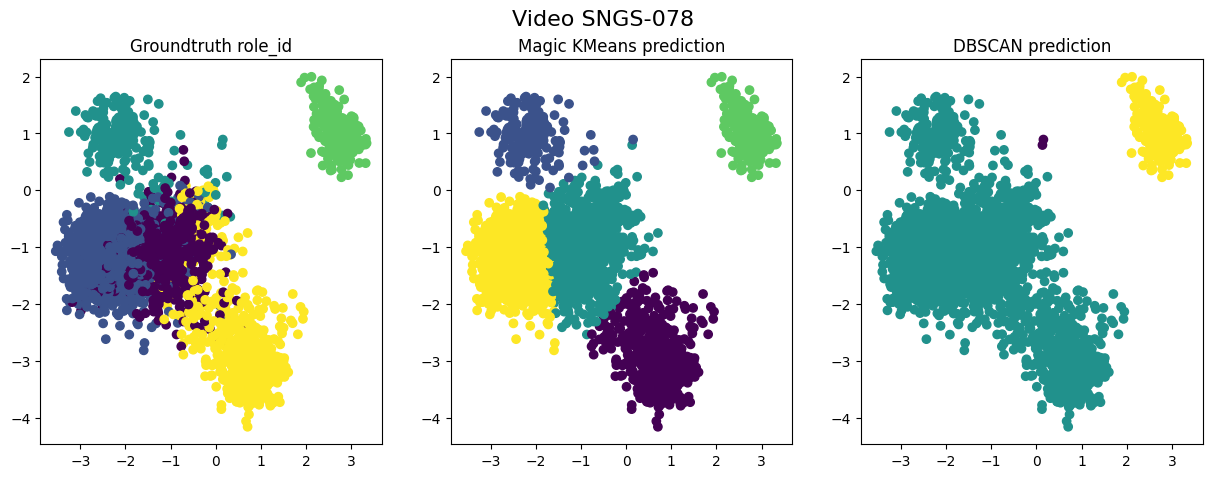

In [28]:
import matplotlib.pyplot as plt
for i in range(len(videos_list)):
    fig, axs = plt.subplots(1, 3, figsize=(15, 5))

    for j in range(3):
        coords = list(labels_coordinates[videos_list[i]].values())
        x_coords = [float(coord[0]) for coord in coords]
        y_coords = [float(coord[1]) for coord in coords]

        if j == 0:
            title = 'Groundtruth role_id'
            role_id = list(groundtruth_role_id[videos_list[i]].values())
            color = [float(role_id) for role_id in role_id]
        elif j == 1:
            title = 'Magic KMeans prediction'
            role_id = list(magic_kmeans_role_id[videos_list[i]].values())
            color = [float(role_id) for role_id in role_id]
        else:
            title = 'DBSCAN prediction'
            role_id = list(dbscan_role_id[videos_list[i]].values())
            color = [float(role_id) for role_id in role_id]

        axs[j].scatter(x_coords, y_coords, c=color)
        axs[j].set_title(title)

    fig.suptitle(f"Video {videos_list[i]}", fontsize=16)
    plt.show()